# 02 · Exercise 1: forecasting `avg_ihs4_next6`

**Task.** Predict each test patient's true average IHS4 for Jan–Jun 2026. Scored by MAE, separately on
test_1 and test_2.

The exploration (notebook 01) showed that recorded scores are biased by visit type, become stale,
often go missing, and that antibiotics reveal flares nobody scored. This notebook answers:

1. How do we turn the records into one row of features per patient?
2. How can we evaluate for test_2 when it has no targets?
3. How good are simple baselines?
4. How well does a gradient-boosting model forecast?
5. What drives the model: clinical signal or recording artefacts?
6. Why will test_2 score worse than test_1?
7. Final model and submission.

In [1]:
TEAM_NAME = "skincaredivas"

import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

DATA, WORK, SUB = Path("public"), Path("work"), Path("submissions")
WORK.mkdir(exist_ok=True); SUB.mkdir(exist_ok=True)
END = pd.Timestamp("2025-12-31")
SPLITS = ["train", "test_1", "test_2"]
SEED = 42
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110})
pd.set_option("display.width", 200)

def letters(axes):
    for a, l in zip(np.ravel(axes), "ABCDEF"):
        a.text(-0.02, 1.03, l, transform=a.transAxes, fontweight="bold", fontsize=14, ha="right", va="bottom")

def load_split(split):
    dates = {"demographics": ["symptom_onset_date", "diagnosis_date"], "visits": ["visit_date"],
             "treatments": ["start_date", "end_date"], "surgeries": ["procedure_date"], "patient_assignment": []}
    return {name: pd.read_csv(DATA / split / f"{name}.csv", parse_dates=cols) for name, cols in dates.items()}

raw = {s: load_split(s) for s in SPLITS}
y_all = pd.read_csv(DATA / "train" / "targets.csv").set_index("patient_id").avg_ihs4_next6

## 1. How do we turn the records into one row of features per patient?

Every feature uses only information that existed on 31 Dec 2025, and **none uses the target**, so train
and test rows are built with the same code. The features answer three questions about each patient:
*how active is the disease now*, *how much should we trust that estimate*, and *what happened that the
scores missed*.

**Two constants come first**, both estimated without the target:
* **Visit-type correction.** Flare and follow-up scores are inflated (notebook 01, Q3). We measure, for
  the same patient in the same year, how much higher they are than scheduled-visit scores, and divide
  by that factor.
* **Practitioner style.** Scoring rate, visit mix and biologic use of each practitioner, computed from
  the practitioner's *other* patients across all three splits. Leaving the patient out matters: a first
  version included the patient's own records, and a classifier could then tell train from test_1 (a
  random holdout!) with AUC 0.65.

In [2]:
SCHED = ["background", "treatment_monitoring"]
VTYPES = SCHED + ["flare_reactive", "follow_up"]

sc = raw["train"]["visits"].dropna(subset=["ihs4_score"]).assign(year=lambda d: d.visit_date.dt.year)
py = sc.groupby(["patient_id", "year", "visit_type"]).ihs4_score.mean().unstack()
base = py[SCHED].mean(axis=1)
TYPE_FACTOR = {t: 1.0 if t in SCHED else float((py[t] / base)[py[t].notna() & base.gt(0)].median()) for t in VTYPES}

def patient_contributions(r):
    """Per-patient sums behind each practitioner statistic (sums can be subtracted to leave a patient out)."""
    v, tr = r["visits"], r["treatments"]
    pa = r["patient_assignment"].merge(r["demographics"][["patient_id", "hurley_stage_baseline"]], on="patient_id").set_index("patient_id")
    open_bio = set(tr[(tr.treatment_class == "Biologic") & tr.end_date.isna()].patient_id)
    c = pd.DataFrame(index=pa.index)
    c["patients"] = 1
    c["visits"] = v.groupby("patient_id").size()
    c["scored"] = v.groupby("patient_id").ihs4_score.count()
    for t in VTYPES:
        c["v_" + t] = (v.visit_type == t).groupby(v.patient_id).sum()
    sv = v[v.visit_type.isin(SCHED)]
    c["sched_sum"] = sv.groupby("patient_id").ihs4_score.sum()
    c["sched_n"] = sv.groupby("patient_id").ihs4_score.count()
    c["hurley"] = pa.hurley_stage_baseline
    c["on_bio"] = c.index.isin(open_bio).astype(int)
    c["abx"] = tr[tr.treatment_class == "Antibiotic"].groupby("patient_id").size()
    c = c.fillna(0)
    c["practitioner_id"] = pa.practitioner_id
    return c

PCONTRIB = pd.concat([patient_contributions(raw[s]) for s in SPLITS])
PTOTAL = PCONTRIB.groupby("practitioner_id").sum()

def practitioner_features(pract_ids):
    t = PTOTAL.reindex(pract_ids.values).set_axis(pract_ids.index) - PCONTRIB.loc[pract_ids.index, PTOTAL.columns]
    f = pd.DataFrame({"pr_score_rate": t.scored / t.visits, "pr_visits_per_patient": t.visits / t.patients,
                      "pr_bio_rate": t.on_bio / t.patients, "pr_abx_per_patient": t.abx / t.patients,
                      "pr_mean_hurley": t.hurley / t.patients, "pr_mean_sched_score": t.sched_sum / t.sched_n}, index=pract_ids.index)
    for vt in VTYPES:
        f["pr_frac_" + vt] = t["v_" + vt] / t.visits
    return f.replace([np.inf, -np.inf], np.nan)

print("visit-type correction factors:", {k: round(v, 3) for k, v in TYPE_FACTOR.items()})

visit-type correction factors: {'background': 1.0, 'treatment_monitoring': 1.0, 'flare_reactive': 1.238, 'follow_up': 1.211}


**Results.** Measured without the target, flare scores are 1.24× and follow-up scores 1.21× the
scheduled scores of the same patient in the same year. This is close to the ~1.25× found against the
target in notebook 01, so the correction is trustworthy.

Now the feature builders, one per data source:
* **Demographics.** Missing values become their own category plus a flag (missingness can carry
  information). The diagnostic delay is recomputed from the two dates when it is blank.
* **Visits and scores.** Recent levels on raw and visit-type-corrected scores; recency-weighted means
  (`neff` = how much evidence they rest on); trend; documentation counts (visits, scoring rate, time since
  the last score, unscored flare visits).
* **Treatments.** Antibiotic counts, separating "orphan" courses with no visit within ±3 days (likely
  out-of-clinic flares); current biologic (drug, line, time on it) and the patient's own response to it.
* **Surgeries.** Counts and recency; outcomes that were not yet knowable on 31 Dec 2025 are masked.

In [3]:
CATS = {"ethnicity": ["White", "Black/African American", "Hispanic/Latino", "Asian", "Other/Unknown", "Missing"],
        "smoking": ["Never", "Former", "Current", "Missing"],
        "family_history": ["No", "Yes", "Unknown", "Missing"],
        "bio_drug": ["None", "Adalimumab", "Secukinumab", "Bimekizumab"]}

def demo_features(d):
    d = d.set_index("patient_id")
    f = pd.DataFrame(index=d.index)
    f["sex_female"] = (d.sex == "Female").astype(int)
    f["age"] = END.year - d.birth_year
    f["age_at_diagnosis"] = d.age_at_diagnosis
    f["years_since_diagnosis"] = (END - d.diagnosis_date).dt.days / 365.25
    f["diagnostic_delay"] = d.diagnostic_delay_years.fillna((d.diagnosis_date - d.symptom_onset_date).dt.days / 365.25)
    f["years_since_onset"] = f.years_since_diagnosis + f.diagnostic_delay
    f["bmi"] = d.bmi_at_baseline
    f["hurley"] = d.hurley_stage_baseline
    for new, col in [("ethnicity", "ethnicity"), ("smoking", "smoking_status"), ("family_history", "family_history_hs")]:
        f[new] = pd.Categorical(d[col].fillna("Missing"), categories=CATS[new])
    for c in ["ethnicity", "bmi_at_baseline", "smoking_status", "symptom_onset_date", "diagnostic_delay_years", "family_history_hs"]:
        f["miss_" + c] = d[c].isna().astype(int)
    return f

def visit_features(v):
    v = v.copy()
    v["age_d"] = (END - v.visit_date).dt.days
    v["scored"] = v.ihs4_score.notna()
    v["is_sched"] = v.visit_type.isin(SCHED)
    v["corr"] = v.ihs4_score / v.visit_type.map(TYPE_FACTOR)
    g = v.groupby("patient_id")
    f = pd.DataFrame({"n_visits": g.size(), "n_scored": g.scored.sum(), "score_rate": g.scored.mean(),
                      "days_since_first_visit": g.age_d.max(), "days_since_last_visit": g.age_d.min()})
    f = f.join(pd.crosstab(v.patient_id, v.visit_type, normalize="index").reindex(columns=VTYPES, fill_value=0).add_prefix("frac_"))
    for w in [90, 180, 365, 730]:
        vw = v[v.age_d < w]; gw = vw.groupby("patient_id")
        f[f"n_visits_{w}d"] = gw.size()
        f[f"n_scored_{w}d"] = gw.scored.sum()
        f[f"mean_score_{w}d"] = gw.ihs4_score.mean()
        f[f"mean_corr_{w}d"] = gw["corr"].mean()
        f[f"mean_sched_{w}d"] = vw[vw.is_sched].groupby("patient_id").ihs4_score.mean()
    for w in [365, 730]:
        vw = v[v.age_d < w]
        f[f"n_flare_visits_{w}d"] = (vw.visit_type == "flare_reactive").groupby(vw.patient_id).sum()
        f[f"n_unscored_flare_{w}d"] = ((vw.visit_type == "flare_reactive") & ~vw.scored).groupby(vw.patient_id).sum()
    s = v[v.scored].sort_values("visit_date"); gs = s.groupby("patient_id")
    f["last_score"] = gs.ihs4_score.last()
    f["last_corr_score"] = gs["corr"].last()
    f["days_since_last_score"] = gs.age_d.last()
    f["last3_mean"] = s.groupby("patient_id").tail(3).groupby("patient_id").ihs4_score.mean()
    f["first3_mean"] = s.groupby("patient_id").head(3).groupby("patient_id").ihs4_score.mean()
    f["mean_score_all"] = gs.ihs4_score.mean()
    f["mean_react_365d"] = s[(s.age_d < 365) & ~s.is_sched].groupby("patient_id").ihs4_score.mean()
    f["max_score_365d"] = s[s.age_d < 365].groupby("patient_id").ihs4_score.max()
    f["sd_score_730d"] = s[s.age_d < 730].groupby("patient_id").ihs4_score.std()
    for hl in [60, 180, 365]:
        w = 0.5 ** (s.age_d / hl)                        # a score loses half its weight every hl days
        sw = w.groupby(s.patient_id).sum()
        f[f"ewm_corr_{hl}"] = (w * s["corr"]).groupby(s.patient_id).sum() / sw
        f[f"neff_{hl}"] = sw
    s2 = s[s.age_d < 730].assign(t=lambda d: -d.age_d / 365.25)   # trend over 2 years (IHS4 points per year)
    s2 = s2.assign(tt=s2.t ** 2, ty=s2.t * s2["corr"])
    a = s2.groupby("patient_id").agg(n=("t", "size"), st=("t", "sum"), sy=("corr", "sum"), stt=("tt", "sum"),
                                     sty=("ty", "sum"), tmin=("t", "min"), tmax=("t", "max"))
    ok = (a.n >= 3) & (a.tmax - a.tmin >= 0.5)
    f["slope_730d"] = ((a.n * a.sty - a.st * a.sy) / (a.n * a.stt - a.st ** 2)).where(ok).clip(-30, 30)
    f["days_since_last_flare_visit"] = v[v.visit_type == "flare_reactive"].groupby("patient_id").age_d.min()
    return f

def treatment_features(tr, v):
    v = v.assign(corr=v.ihs4_score / v.visit_type.map(TYPE_FACTOR))
    ab = tr[tr.treatment_class == "Antibiotic"].assign(age_d=lambda x: (END - x.start_date).dt.days)
    near = ab[["treatment_id", "patient_id", "start_date"]].merge(v[["patient_id", "visit_date"]], on="patient_id")
    ab["orphan"] = ~ab.treatment_id.isin(near[(near.start_date - near.visit_date).dt.days.abs() <= 3].treatment_id)
    f = pd.DataFrame(index=pd.Index(tr.patient_id.unique(), name="patient_id"))
    f["days_since_last_abx"] = ab.groupby("patient_id").age_d.min()
    f["n_abx_total"] = ab.groupby("patient_id").size()
    f["n_orphan_abx_total"] = ab.groupby("patient_id").orphan.sum()
    f["n_oral_abx_365d"] = ab[(ab.age_d < 365) & (ab.route == "Oral")].groupby("patient_id").size()
    for w in [180, 365, 730]:
        aw = ab[ab.age_d < w].groupby("patient_id")
        f[f"n_abx_{w}d"] = aw.size()
        f[f"n_orphan_abx_{w}d"] = aw.orphan.sum()
    bio = tr[tr.treatment_class == "Biologic"]
    cur = bio[bio.end_date.isna()].set_index("patient_id")
    f["on_bio"] = f.index.isin(cur.index).astype(int)
    f["ever_bio"] = f.index.isin(bio.patient_id).astype(int)
    f["n_prior_bio"] = bio[bio.end_date.notna()].groupby("patient_id").size()
    f["bio_line"] = cur.treatment_line
    f["bio_drug"] = cur.drug_name
    f["days_on_bio"] = (END - cur.start_date).dt.days
    f["days_since_bio_stop"] = (END - bio[bio.end_date.notna()].groupby("patient_id").end_date.max()).dt.days.where(f.on_bio == 0)
    vs = v.dropna(subset=["ihs4_score"]).merge(cur[["start_date"]], left_on="patient_id", right_index=True)
    dd = (vs.visit_date - vs.start_date).dt.days
    f["bio_pre_mean"] = vs[(dd < 0) & (dd >= -365)].groupby("patient_id")["corr"].mean()   # year before the line
    f["bio_early_mean"] = vs[(dd >= 30) & (dd < 180)].groupby("patient_id")["corr"].mean()  # months 1-6
    f["bio_post_mean"] = vs[dd >= 90].groupby("patient_id")["corr"].mean()
    f["bio_early_ratio"] = f.bio_early_mean / f.bio_pre_mean.clip(lower=1)
    f["bio_post_ratio"] = f.bio_post_mean / f.bio_pre_mean.clip(lower=1)
    return f

def surgery_features(sg):
    sg = sg.assign(age_d=lambda x: (END - x.procedure_date).dt.days)
    sg.loc[sg.age_d < 183, "recurrence_within_6mo"] = np.nan                       # not yet knowable
    sg.loc[sg.age_d < sg.wound_healing_weeks * 7, "wound_healing_weeks"] = np.nan  # not yet knowable
    g = sg.groupby("patient_id")
    f = pd.DataFrame({"n_surg_total": g.size(), "days_since_last_surgery": g.age_d.min(),
                      "surg_recurrence_rate": g.recurrence_within_6mo.mean(), "surg_mean_healing_weeks": g.wound_healing_weeks.mean()})
    f["n_surg_365d"] = sg[sg.age_d < 365].groupby("patient_id").size()
    f["n_incision_drainage_365d"] = sg[(sg.age_d < 365) & (sg.procedure_type == "Incision & drainage")].groupby("patient_id").size()
    return f

The last step joins everything and adds one hand-built feature, the **shrinkage level** `eb_level`:
the patient's recency-weighted corrected score, pulled toward the average of patients with the same
Hurley stage and biologic status. The less recent evidence (`neff`), the stronger the pull, and a
patient with no score gets the group average:

`eb_level = (neff · own level + 2 · group prior) / (neff + 2)`

In [4]:
def assemble(r):
    f = demo_features(r["demographics"])
    f = f.join(visit_features(r["visits"])).join(treatment_features(r["treatments"], r["visits"])).join(surgery_features(r["surgeries"]))
    f = f.join(r["patient_assignment"].set_index("patient_id").practitioner_id)
    f = f.join(practitioner_features(f.practitioner_id)).copy()
    zero = [c for c in f if c.startswith(("n_", "neff_")) or c in ("on_bio", "ever_bio")]
    f[zero] = f[zero].fillna(0)
    f["bio_drug"] = pd.Categorical(f.bio_drug.fillna("None"), categories=CATS["bio_drug"])
    f["bio_line"] = f.bio_line.fillna(0)
    return f

feats = {s: assemble(raw[s]) for s in SPLITS}
PRIOR = feats["train"].groupby(["hurley", "on_bio"]).ewm_corr_180.mean()

def add_eb(f, k=2.0):
    prior = pd.Series(list(zip(f.hurley, f.on_bio)), index=f.index).map(PRIOR)
    f["eb_prior"] = prior
    f["eb_level"] = (f.neff_180 * f.ewm_corr_180.fillna(prior) + k * prior) / (f.neff_180 + k)
    return f

feats = {s: add_eb(f) for s, f in feats.items()}
FEATS = [c for c in feats["train"] if c != "practitioner_id"]
print({s: f.shape for s, f in feats.items()}, "|", len(FEATS), "model features")
print(PRIOR.round(2).to_dict())

{'train': (21000, 108), 'test_1': (4000, 108), 'test_2': (6228, 108)} | 107 model features
{(1, 0.0): 4.88, (2, 0.0): 10.11, (2, 1.0): 6.3, (3, 0.0): 17.18, (3, 1.0): 13.38}


**Results.** Every split now has one row per patient with 107 model features, built with identical code.

The priors that sparse patients are pulled toward:
* Hurley 1 untreated ≈ 4.9;
* Hurley 2: 10.1 untreated vs 6.3 on a biologic;
* Hurley 3: 17.2 untreated vs 13.4 on a biologic.

The gap between treated and untreated patients within each stage is why the prior is split by biologic
status.

## 2. How can we evaluate for test_2 when it has no targets?

Notebook 01 showed that test_2 differs in **who** the patients are (more women, more Black patients,
younger) and in **how they are documented** (fewer visits and scores, concentrated in Black patients and
patients with missing ethnicity). We rebuild both differences on train, giving a **pseudo‑test_2**:
* **Documentation:** per ethnicity and visit type, we erase scores and drop visits at test_2's rates,
  then rebuild the features from the thinned records.
* **Population:** a classifier separating train from test_2 on demographics gives each train patient a
  weight `p / (1 − p)`; weighted train then looks like test_2's population.

In [5]:
def doc_profile(split):
    v = raw[split]["visits"].merge(raw[split]["demographics"][["patient_id", "ethnicity"]], on="patient_id")
    v["ethnicity"] = v.ethnicity.fillna("Missing")
    rate = v.groupby(["ethnicity", "visit_type"]).ihs4_score.apply(lambda x: x.notna().mean())
    n_pat = raw[split]["demographics"].ethnicity.fillna("Missing").value_counts()
    return rate, v.groupby("ethnicity").size() / n_pat

rate_tr, vpp_tr = doc_profile("train"); rate_t2, vpp_t2 = doc_profile("test_2")
KEEP_SCORE, KEEP_VISIT = (rate_t2 / rate_tr).clip(upper=1), (vpp_t2 / vpp_tr).clip(upper=1)

rng = np.random.default_rng(SEED)
vs = raw["train"]["visits"].merge(raw["train"]["demographics"][["patient_id", "ethnicity"]], on="patient_id")
vs["ethnicity"] = vs.ethnicity.fillna("Missing")
vs = vs[rng.random(len(vs)) < vs.ethnicity.map(KEEP_VISIT).values].copy()
p_keep = pd.Series(list(zip(vs.ethnicity, vs.visit_type)), index=vs.index).map(KEEP_SCORE).values
vs.loc[rng.random(len(vs)) >= p_keep, "ihs4_score"] = np.nan
raw_sim = dict(raw["train"]); raw_sim["visits"] = vs.drop(columns="ethnicity")
feats["train_sim"] = add_eb(assemble(raw_sim)).loc[feats["train"].index]

DEMO = ["sex_female", "age", "age_at_diagnosis", "bmi", "hurley", "ethnicity", "smoking", "family_history",
        "diagnostic_delay", "years_since_diagnosis"] + [c for c in FEATS if c.startswith("miss_")]

def adversarial(a, b, cols):
    """Out-of-fold P(row belongs to b) for a classifier separating a from b; returns AUC and the OOF probabilities."""
    X = pd.concat([a[cols], b[cols]]); lab = np.r_[np.zeros(len(a)), np.ones(len(b))]
    p = np.zeros(len(X))
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, lab):
        m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50, verbose=-1)
        p[va_i] = m.fit(X.iloc[tr_i], lab[tr_i]).predict_proba(X.iloc[va_i])[:, 1]
    return roc_auc_score(lab, p), p[: len(a)]

auc_demo_t2, p_t2 = adversarial(feats["train"], feats["test_2"], DEMO)
p_t2 = np.clip(p_t2, 0.01, 0.99)
W2 = (p_t2 / (1 - p_t2)); W2 = np.clip(W2 / W2.mean(), 0.05, 20); W2 = W2 / W2.mean()

print("probability of keeping a visit by ethnicity:", KEEP_VISIT.round(2).to_dict())
print("share of visits scored — train / thinned train / test_2:",
      round(raw["train"]["visits"].ihs4_score.notna().mean(), 3), round(vs.ihs4_score.notna().mean(), 3),
      round(raw["test_2"]["visits"].ihs4_score.notna().mean(), 3))
tw = feats["train"]
print(f"demographic AUC train vs test_2: {auc_demo_t2:.3f} | weighted train: female {np.average(tw.sex_female, weights=W2):.3f} "
      f"(test_2 {feats['test_2'].sex_female.mean():.3f}), Black {np.average(tw.ethnicity == 'Black/African American', weights=W2):.3f} "
      f"(test_2 {(feats['test_2'].ethnicity == 'Black/African American').mean():.3f})")

probability of keeping a visit by ethnicity: {'Asian': 0.99, 'Black/African American': 0.79, 'Hispanic/Latino': 0.98, 'Missing': 0.81, 'Other/Unknown': 0.92, 'White': 0.95}
share of visits scored — train / thinned train / test_2: 0.643 0.562 0.514
demographic AUC train vs test_2: 0.710 | weighted train: female 0.890 (test_2 0.893), Black 0.538 (test_2 0.538)


**Results.**

* **Documentation.** Black patients and patients with missing ethnicity keep ~80 % of their visits and
  lose about a third of their scores; other groups are almost untouched. The train scoring rate drops from
  0.64 to 0.56. test_2 is at 0.51, and the rest of the gap is test_2's larger share of Black patients,
  which the weights add.
* **Population.** Demographics separate train from test_2 with AUC 0.71. After weighting, train matches
  test_2's share of women (89.0 % vs 89.3 %) and of Black patients (53.8 % vs 53.8 %).

## 3. How good are simple baselines?

The brief names three baselines: the population mean, the Hurley-stage mean and carrying the recent
scores forward. We add our shrinkage level `eb_level`, which uses no machine learning. All are scored
with **5-fold cross-validation** (each patient predicted by a model that never saw them), on train as it
is (**test_1 proxy**) and on the pseudo‑test_2. We use medians, because MAE is minimised by the median.

In [6]:
ids = feats["train"].index
y = y_all.loc[ids].values
folds = np.zeros(len(y), int)
for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(y, pd.qcut(y, 10, labels=False))):
    folds[va] = k

def band(x):
    return np.digitize(x, [3 + 1e-9, 11])           # 0 mild (≤3), 1 moderate, 2 severe (≥11)

def score(p_orig, p_sim):
    return {"MAE test_1 proxy": np.abs(p_orig - y).mean(), "MAE pseudo-test_2": np.average(np.abs(p_sim - y), weights=W2),
            "band accuracy": (band(p_orig) == band(y)).mean()}

def oof_group_median(key):
    out = np.zeros(len(y))
    for k in range(5):
        tr, va = folds != k, folds == k
        out[va] = pd.Series(key[va]).map(pd.Series(y[tr]).groupby(key[tr]).median()).values
    return out

hur = oof_group_median(feats["train"].hurley.values)
results = {
    "population median": score(oof_group_median(np.zeros(len(y))), oof_group_median(np.zeros(len(y)))),
    "Hurley-stage median": score(hur, hur),
    "carry forward last 3 scores": score(feats["train"].last3_mean.fillna(pd.Series(hur, ids)).values,
                                         feats["train_sim"].last3_mean.fillna(pd.Series(hur, ids)).values),
    "shrinkage level (eb_level)": score(feats["train"].eb_level.values, feats["train_sim"].eb_level.values),
}
pd.DataFrame(results).T.round(3)

,MAE test_1 proxy,MAE pseudo-test_2,band accuracy
population median,4.334,4.435,0.552
Hurley-stage median,2.667,2.814,0.726
carry forward last 3 scores,2.574,2.824,0.754
shrinkage level (eb_level),1.909,2.027,0.760


**Results.**

* The brief's baselines reach MAE 4.33 (population), 2.67 (Hurley) and 2.57 (carry-forward) on the
  test_1 proxy.
* Carry-forward suffers most from thinning (2.82), because it has nothing to fall back on.
* **The shrinkage level alone reaches 1.91 / 2.03.** Correcting for visit type and pulling sparse patients
  toward a prior is worth about 0.7 MAE before any machine learning.

## 4. How well does a gradient-boosting model forecast?

**LightGBM** builds hundreds of small decision trees, each correcting the errors of the previous ones.
It handles missing values natively (each split learns where missing values should go), so no imputation
is needed. We use the **Huber loss**: squared for errors below 3 points, linear above, which keeps a few
extreme patients from dominating and behaves close to MAE. The number of trees is chosen by early
stopping inside cross-validation.

trees per fold: [538, 256, 419, 371, 369]


MAE test_1 proxy  1.432 95% CI [1.412 1.452]


MAE pseudo-test_2 1.579 95% CI [1.549 1.614]


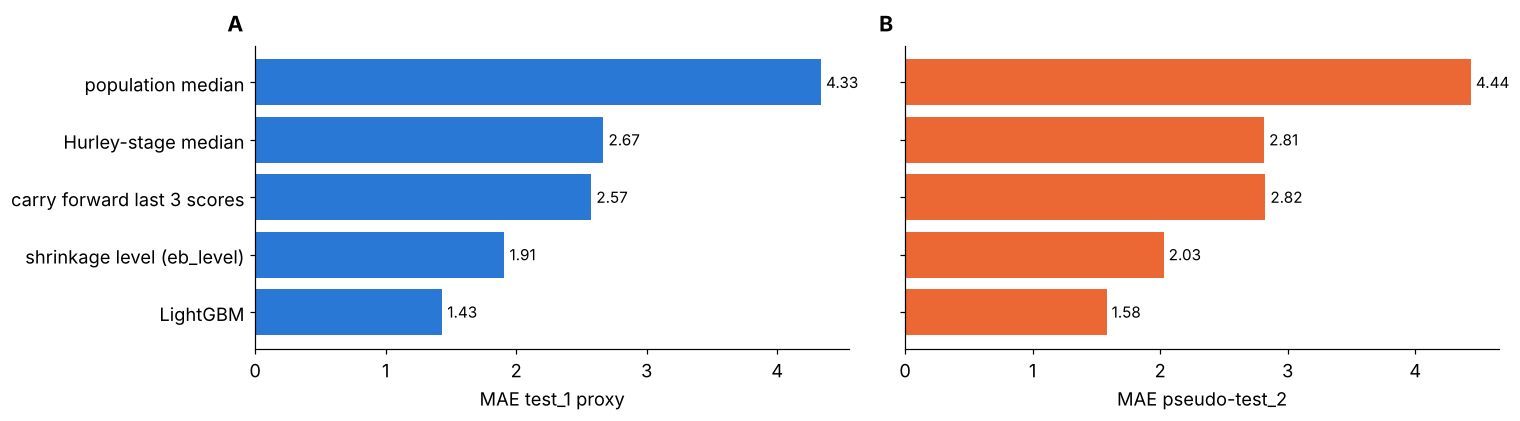

In [7]:
PARAMS = dict(objective="huber", alpha=3.0, learning_rate=0.05, num_leaves=31, min_data_in_leaf=50,
              feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED)

pred_o, pred_s, iters = np.zeros(len(y)), np.zeros(len(y)), []
for k in range(5):
    tr, va = folds != k, folds == k
    dval = lgb.Dataset(pd.concat([feats["train"][FEATS][va], feats["train_sim"][FEATS][va]]), np.r_[y[va], y[va]])
    m = lgb.train(PARAMS, lgb.Dataset(feats["train"][FEATS][tr], y[tr]), 4000, valid_sets=[dval],
                  callbacks=[lgb.early_stopping(200, verbose=False)])
    iters.append(m.best_iteration)
    pred_o[va] = m.predict(feats["train"][FEATS][va], num_iteration=m.best_iteration)
    pred_s[va] = m.predict(feats["train_sim"][FEATS][va], num_iteration=m.best_iteration)

def boot_ci(err, w=None, n=1000):
    r = np.random.default_rng(SEED); w = np.ones(len(err)) if w is None else w
    i = r.integers(0, len(err), (n, len(err)))
    return np.percentile((err[i] * w[i]).sum(1) / w[i].sum(1), [2.5, 97.5])

results["LightGBM"] = score(pred_o, pred_s)
print("trees per fold:", iters)
print("MAE test_1 proxy ", round(np.abs(pred_o - y).mean(), 3), "95% CI", boot_ci(np.abs(pred_o - y)).round(3))
print("MAE pseudo-test_2", round(np.average(np.abs(pred_s - y), weights=W2), 3), "95% CI", boot_ci(np.abs(pred_s - y), W2).round(3))

tab = pd.DataFrame(results).T
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = tab.index[::-1]
for a, col, c in zip(ax, ["MAE test_1 proxy", "MAE pseudo-test_2"], PAL):
    a.barh(order, tab.loc[order, col], color=c); a.set_xlabel(col)
    for i, v in enumerate(tab.loc[order, col]):
        a.text(v + 0.04, i, f"{v:.2f}", va="center", fontsize=10)
ax[1].set_yticklabels([])
letters(ax); plt.tight_layout(); plt.show()

**Results.** **LightGBM reaches MAE 1.43 (95 % CI 1.41–1.45) on the test_1 proxy and 1.58 (1.55–1.61) on the
pseudo‑test_2.**
* That is 44 % below the best baseline from the brief on both.
* 83 % of patients are placed in the right severity band (75 % for carry-forward).

Where are the errors? We split the out-of-fold error by how many scores the patient had last year and
by true severity band.

In [8]:
ev = pd.DataFrame({"err": np.abs(pred_o - y), "err_thinned": np.abs(pred_s - y), "y": y,
                   "recent scores": pd.cut(feats["train"].n_scored_365d.values, [-1, 0, 2, 5, 10, 1e9], labels=["0", "1-2", "3-5", "6-10", ">10"]),
                   "true band": pd.Categorical(np.array(["mild", "moderate", "severe"])[band(y)], ["mild", "moderate", "severe"])})
t1 = ev.groupby("recent scores", observed=True).agg(n=("err", "size"), MAE=("err", "mean"), MAE_thinned=("err_thinned", "mean"))
t2 = ev.groupby("true band", observed=True).agg(n=("err", "size"), MAE=("err", "mean"), mean_target=("y", "mean"))
t2["relative error"] = t2.MAE / t2.mean_target
print(t1.round(2)); print(); print(t2.round(2))

                  n   MAE  MAE_thinned
recent scores                         
0              4068  1.54         1.56
1-2            5896  1.41         1.47
3-5            5565  1.35         1.40
6-10           4016  1.41         1.45
>10            1455  1.60         1.64

               n   MAE  mean_target  relative error
true band                                          
mild        3354  1.08         2.01            0.54
moderate   11600  1.19         6.39            0.19
severe      6046  2.08        15.53            0.13


**Results.**

* **Documentation.** Error is lowest with 3–5 recent scores (1.34) and highest with none (1.54). Very
  heavily scored patients (>10) are also harder (1.59): they are the most active, seen mostly in flares.
  Thinning adds 0.02–0.06 in every group.
* **Severity.** Absolute error grows with severity (1.08 mild → 2.08 severe), while relative error falls
  (54 % → 13 %).

## 5. What drives the model: clinical signal or recording artefacts?

SHAP values split each prediction into one contribution per feature. We group the features into
families: **recent severity** (IHS4 levels, trend, Hurley), **hidden flares** (antibiotics, flare
visits, surgeries), **treatment**, **demographics**, and **documentation** (visit counts, scoring rate,
missing flags, practitioner style). Documentation describes *how a patient was recorded*, not their
disease. To test whether the model *needs* it, we also retrain without that family.

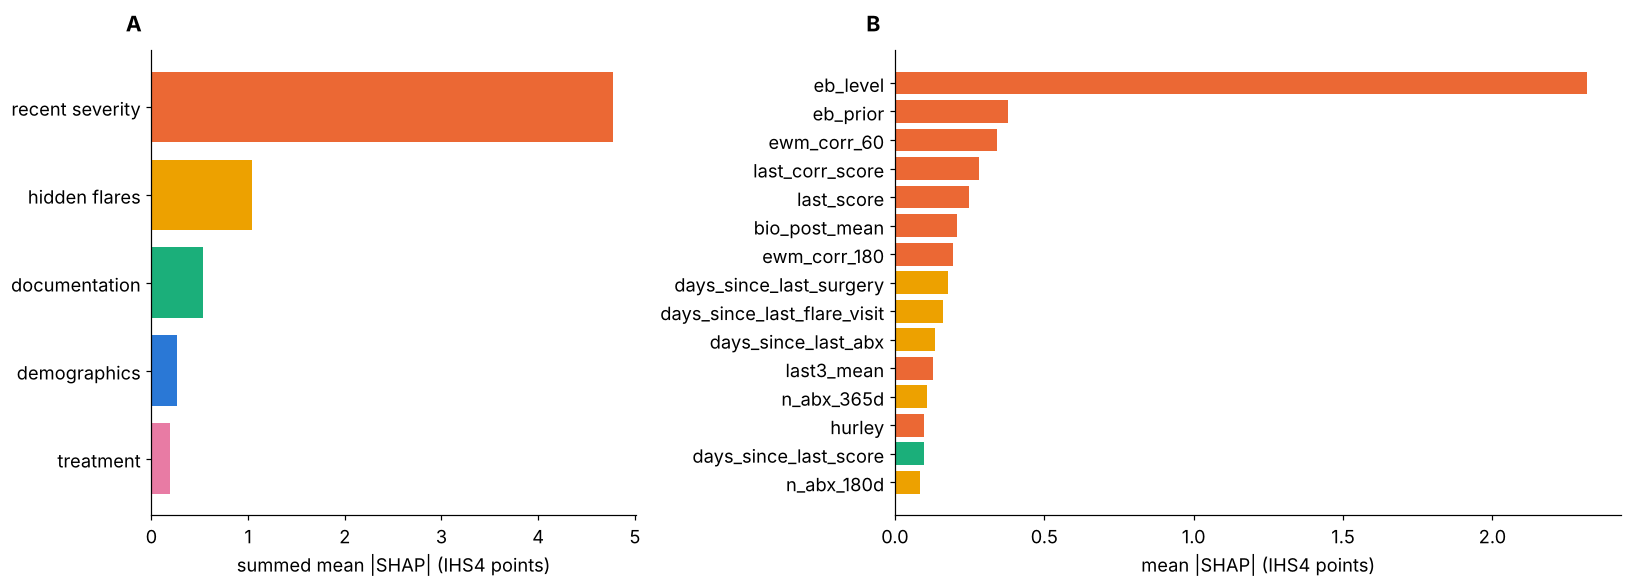

share of attribution by family: {'recent severity': 0.701, 'hidden flares': 0.154, 'documentation': 0.079, 'demographics': 0.039, 'treatment': 0.028}
without documentation features: {'MAE test_1 proxy': np.float64(1.434), 'MAE pseudo-test_2': np.float64(1.579), 'band accuracy': np.float64(0.829)}


In [9]:
def family(c):
    if c.startswith(("pr_", "miss_", "frac_", "neff_", "n_visits", "n_scored")) or c in (
            "score_rate", "days_since_first_visit", "days_since_last_visit", "days_since_last_score"):
        return "documentation"
    if c.startswith(("n_abx", "n_orphan", "days_since_last_abx", "n_flare", "n_unscored", "days_since_last_flare",
                     "n_surg", "n_incision", "days_since_last_surgery", "surg_")):
        return "hidden flares"
    if c in ("on_bio", "ever_bio", "bio_drug", "bio_line", "days_on_bio", "n_prior_bio", "days_since_bio_stop"):
        return "treatment"
    if c in ("sex_female", "age", "age_at_diagnosis", "years_since_diagnosis", "diagnostic_delay", "years_since_onset",
             "bmi", "ethnicity", "smoking", "family_history"):
        return "demographics"
    return "recent severity"

FAMILY = pd.Series({c: family(c) for c in FEATS})
N_ROUNDS = int(np.mean(iters) * 1.1)
models = [lgb.train({**PARAMS, "seed": SEED + s}, lgb.Dataset(feats["train"][FEATS], y), N_ROUNDS) for s in range(3)]

sample = feats["train"][FEATS].sample(5000, random_state=SEED)
shap = pd.DataFrame(np.mean([m.predict(sample, pred_contrib=True) for m in models], axis=0)[:, :-1], columns=FEATS)
imp = shap.abs().mean().sort_values(ascending=False)
fam = imp.groupby(FAMILY).sum().sort_values()
FAM_COL = {"recent severity": PAL[1], "hidden flares": PAL[3], "documentation": PAL[2], "demographics": PAL[0], "treatment": PAL[4]}

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [0.8, 1.2]})
ax[0].barh(fam.index, fam.values, color=[FAM_COL[f] for f in fam.index]); ax[0].set_xlabel("summed mean |SHAP| (IHS4 points)")
top = imp.head(15)[::-1]
ax[1].barh(top.index, top.values, color=[FAM_COL[FAMILY[c]] for c in top.index]); ax[1].set_xlabel("mean |SHAP| (IHS4 points)")
letters(ax); plt.tight_layout(); plt.show()

no_doc = [c for c in FEATS if FAMILY[c] != "documentation"]
p_nd = np.zeros(len(y)); p_nd_s = np.zeros(len(y))
for k in range(5):
    tr, va = folds != k, folds == k
    m = lgb.train(PARAMS, lgb.Dataset(feats["train"][no_doc][tr], y[tr]), int(np.mean(iters)))
    p_nd[va] = m.predict(feats["train"][no_doc][va]); p_nd_s[va] = m.predict(feats["train_sim"][no_doc][va])
print("share of attribution by family:", (fam / fam.sum()).round(3).sort_values(ascending=False).to_dict())
print("without documentation features:", {k: round(v, 3) for k, v in score(p_nd, p_nd_s).items()})

**Results.**

* **70 % of the attribution is recent severity**, led by the shrinkage level and its Hurley × biologic
  prior.
* **15 % is hidden-flare traces**, mainly time since the last surgery, flare visit and antibiotic course.
* Documentation 8 %, demographics 4 %, treatment 3 % (already inside the prior).
* **Without the documentation family, MAE is unchanged** (1.434 / 1.579). The model uses recording
  artefacts only to fine-tune how much it trusts the clinical signal, and does not depend on them. That
  makes it safer to transfer to sites that document differently.

## 6. Why will test_2 score worse than test_1?

Two tools:
* **Adversarial validation.** A classifier tries to tell train from each test set, using one block of
  features at a time. AUC 0.5 = indistinguishable; higher = that block has shifted.
* **Error decomposition.** We re-score the out-of-fold errors under the population shift only
  (reweighting), the documentation shift only (thinned records), and both.

In [10]:
BLOCKS = {"demographics": DEMO,
          "documentation": [c for c in FEATS if FAMILY[c] == "documentation" and not c.startswith(("pr_", "miss_"))],
          "recent severity": [c for c in FEATS if FAMILY[c] == "recent severity"],
          "hidden flares": [c for c in FEATS if FAMILY[c] == "hidden flares"],
          "treatment": [c for c in FEATS if FAMILY[c] == "treatment"],
          "all features": FEATS}
adv = pd.DataFrame({t: {b: adversarial(feats["train"], feats[t], cols)[0] for b, cols in BLOCKS.items()} for t in ["test_1", "test_2"]})

within = {}
for eth in ["White", "Black/African American", "Missing"]:
    a, b = feats["train"][feats["train"].ethnicity == eth], feats["test_2"][feats["test_2"].ethnicity == eth]
    within[eth] = adversarial(a, b, BLOCKS["documentation"])[0]

e_o, e_s = np.abs(pred_o - y), np.abs(pred_s - y)
scen = pd.DataFrame({"expected MAE": [e_o.mean(), np.average(e_o, weights=W2), e_s.mean(), np.average(e_s, weights=W2)]},
                    index=["test_1 proxy", "population shift only", "documentation shift only", "both (pseudo-test_2)"])
print("documentation AUC train vs test_2 within ethnicity:", {k: round(v, 3) for k, v in within.items()})
print(scen.round(3)); print()
adv.round(3)

documentation AUC train vs test_2 within ethnicity: {'White': 0.543, 'Black/African American': 0.728, 'Missing': 0.682}
                          expected MAE
test_1 proxy                     1.432
population shift only            1.505
documentation shift only         1.477
both (pseudo-test_2)             1.579



,test_1,test_2
demographics,0.502,0.710
documentation,0.503,0.676
recent severity,0.506,0.643
hidden flares,0.485,0.629
treatment,0.508,0.498
all features,0.502,0.741


**Results.**

* **test_1 is a clean random holdout.** Every block has AUC ≈ 0.50.
* **test_2 has shifted in demographics (AUC 0.71) and documentation (0.68).** Treatment has not shifted
  (0.50).
  * Severity and flare features (0.62–0.64) differ only because they rest on fewer scores; their average
    level is the same.
  * Within the same ethnicity, documentation separates test_2 from train for Black patients (0.73) and
    patients with missing ethnicity (0.68), but hardly for White patients (0.54). The documentation loss
    is targeted, not just a different mix of patients.
* **Cost.** The population shift alone raises expected MAE from 1.43 to 1.50, the documentation shift
  alone to 1.48, and both together to **1.58**.
  * The population costs accuracy because women and Black patients have slightly higher averages, and
    absolute errors grow with disease level.
  * **Expect test_2 to score roughly 0.07–0.15 worse than test_1.**

## 7. Final model and submission

The final model is trained on all 21,000 train patients with the number of trees found in CV, averaged
over 3 random seeds (these are the `models` already fitted in section 5). We save the features,
out-of-fold predictions and test predictions for notebooks 03 and 04.

In [11]:
predict = lambda X: np.clip(np.mean([m.predict(X[FEATS]) for m in models], axis=0), 0, None)
pred = pd.concat([pd.Series(predict(feats[s]), feats[s].index) for s in ["test_1", "test_2"]])

tmpl = pd.read_csv(DATA / "evaluation_templates" / "answers_teamName_exercise1.csv")
sub = tmpl[["patient_id"]].assign(pred_avg_ihs4_next6=tmpl.patient_id.map(pred).round(4))
assert sub.pred_avg_ihs4_next6.notna().all() and len(sub) == len(tmpl)
sub.to_csv(SUB / f"answers_{TEAM_NAME}_exercise1.csv", index=False)

for s, f in feats.items():
    f.to_parquet(WORK / f"features_{s}.parquet")
raw_sim["visits"].to_parquet(WORK / "visits_train_sim.parquet")
pd.DataFrame({"pred_orig": pred_o, "pred_sim": pred_s, "fold": folds, "y": y, "w_test2": W2}, index=ids).to_parquet(WORK / "oof_ex1.parquet")
pred.rename("pred").to_frame().to_parquet(WORK / "pred_ex1.parquet")
for i, m in enumerate(models):
    m.save_model(str(WORK / f"ex1_model_{i}.txt"))
json.dump({"features": FEATS, "params": PARAMS, "n_rounds": N_ROUNDS, "type_factor": TYPE_FACTOR}, open(WORK / "ex1_config.json", "w"), indent=1)

print(sub.shape, "->", SUB / f"answers_{TEAM_NAME}_exercise1.csv")
print("mean prediction:", {s: round(pred.loc[feats[s].index].mean(), 2) for s in ["test_1", "test_2"]}, "| train mean target", round(y.mean(), 2))

(10228, 2) -> submissions/answers_skincaredivas_exercise1.csv
mean prediction: {'test_1': np.float64(8.24), 'test_2': np.float64(8.39)} | train mean target 8.32


**Results.** The submission file has all 10,228 template patients. Mean predictions (8.24 test_1, 8.39 test_2) are
close to the train mean of 8.32; test_2 is slightly higher, consistent with its population. Features,
out-of-fold predictions and models are saved in `work/` for notebooks 03 and 04.